In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Load dataset (205 rows, 26 columns, no header row, '?' indicates missing values)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"
columns = [
    "symboling",
    "normalized-losses",
    "make",
    "fuel-type",
    "aspiration",
    "num-of-doors",
    "body-style",
    "drive-wheels",
    "engine-location",
    "wheel-base",
    "length",
    "width",
    "height",
    "curb-weight",
    "engine-type",
    "num-of-cylinders",
    "engine-size",
    "fuel-system",
    "bore",
    "stroke",
    "compression-ratio",
    "horsepower",
    "peak-rpm",
    "city-mpg",
    "highway-mpg",
    "price",
]

df = pd.read_csv(url, names=columns, na_values="?")

# Convert numeric specification columns stored as strings/objects
for col in ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm", "price"]:
  df[col] = pd.to_numeric(df[col], errors="coerce")

# 2. Required initial inspection
print("Shape (rows, columns):", df.shape)
print("\n--- First 5 rows (head) ---")
print(df.head())

print("\n--- Last 5 rows (tail) ---")
print(df.tail())

print("\n--- Data types and non-null counts (info) ---")
print(df.info())

print("\n--- Summary statistics (describe) ---")
print(df.describe(include="all"))

Shape (rows, columns): (205, 26)

--- First 5 rows (head) ---
   symboling  normalized-losses         make fuel-type aspiration  \
0          3                NaN  alfa-romero       gas        std   
1          3                NaN  alfa-romero       gas        std   
2          1                NaN  alfa-romero       gas        std   
3          2              164.0         audi       gas        std   
4          2              164.0         audi       gas        std   

  num-of-doors   body-style drive-wheels engine-location  wheel-base  ...  \
0          two  convertible          rwd           front        88.6  ...   
1          two  convertible          rwd           front        88.6  ...   
2          two    hatchback          rwd           front        94.5  ...   
3         four        sedan          fwd           front        99.8  ...   
4         four        sedan          4wd           front        99.4  ...   

   engine-size  fuel-system  bore  stroke compression-ratio 

In [7]:
# Question 5: Identify columns with missing values and count them
missing_counts = df.isnull().sum()
missing_cols = missing_counts[missing_counts > 0].sort_values(ascending=False)
print("\n--- Question 5: Columns with missing values ---")
print(missing_cols)

# Check duplicate rows
duplicate_count = df.duplicated().sum()
print("\nDuplicate rows count:", duplicate_count)

# Question 2: Average, minimum, and maximum car prices using a NumPy array
valid_prices_arr = df["price"].dropna().to_numpy()
avg_price = np.mean(valid_prices_arr)
min_price = np.min(valid_prices_arr)
max_price = np.max(valid_prices_arr)

print("\n--- Question 2: Car Price Statistics (NumPy) ---")
print(f"Average Price: ${avg_price:,.2f}")
print(f"Minimum Price: ${min_price:,.2f}")
print(f"Maximum Price: ${max_price:,.2f}")


--- Question 5: Columns with missing values ---
normalized-losses    41
bore                  4
stroke                4
price                 4
num-of-doors          2
horsepower            2
peak-rpm              2
dtype: int64

Duplicate rows count: 0

--- Question 2: Car Price Statistics (NumPy) ---
Average Price: $13,207.13
Minimum Price: $5,118.00
Maximum Price: $45,400.00


In [8]:
# Question 1: Car manufacturers that appear most often
make_counts = df["make"].value_counts()
print("\n--- Question 1: Top Car Manufacturers by Count ---")
print(make_counts)

# Question 3: Body style with the highest average price
body_avg_price = (
    df.dropna(subset=["price"])
    .groupby("body-style")["price"]
    .mean()
    .sort_values(ascending=False)
)
print("\n--- Question 3: Average Price by Body Style ---")
print(body_avg_price)
print(
    f"Highest average price body style: {body_avg_price.index[0]}"
    f" (${body_avg_price.iloc[0]:,.2f})"
)

# Question 4: Compare average engine size across fuel types
fuel_engine_stats = (
    df.groupby("fuel-type")["engine-size"]
    .agg(count="count", avg_engine_size="mean", median_engine_size="median")
    .sort_values(by="avg_engine_size", ascending=False)
)
print("\n--- Question 4: Engine Size Across Fuel Types ---")
print(fuel_engine_stats)

# Question 6: 10 most expensive cars (using filtering + sorting)
priced_cars = df[df["price"].notna()]
top_10_expensive = priced_cars.sort_values(by="price", ascending=False).head(10)[
    ["make", "body-style", "fuel-type", "engine-size", "horsepower", "price"]
]
print("\n--- Question 6: 10 Most Expensive Cars ---")
print(top_10_expensive.to_string(index=False))


--- Question 1: Top Car Manufacturers by Count ---
make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
subaru           12
volkswagen       12
volvo            11
peugot           11
dodge             9
mercedes-benz     8
bmw               8
audi              7
plymouth          7
saab              6
porsche           5
isuzu             4
alfa-romero       3
chevrolet         3
jaguar            3
renault           2
mercury           1
Name: count, dtype: int64

--- Question 3: Average Price by Body Style ---
body-style
hardtop        22208.500000
convertible    21890.500000
sedan          14459.755319
wagon          12371.960000
hatchback       9957.441176
Name: price, dtype: float64
Highest average price body style: hardtop ($22,208.50)

--- Question 4: Engine Size Across Fuel Types ---
           count  avg_engine_size  median_engine_size
fuel-type                                            
diesel        20       135.700000  

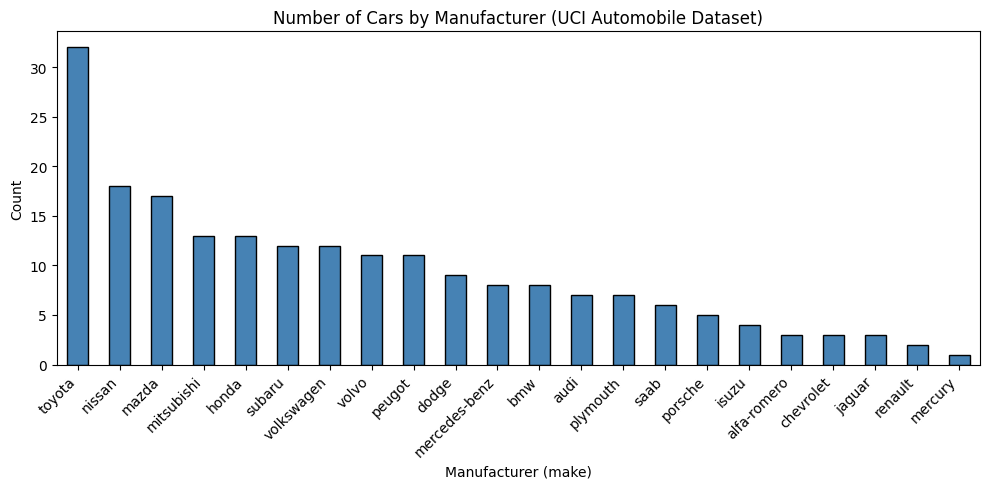

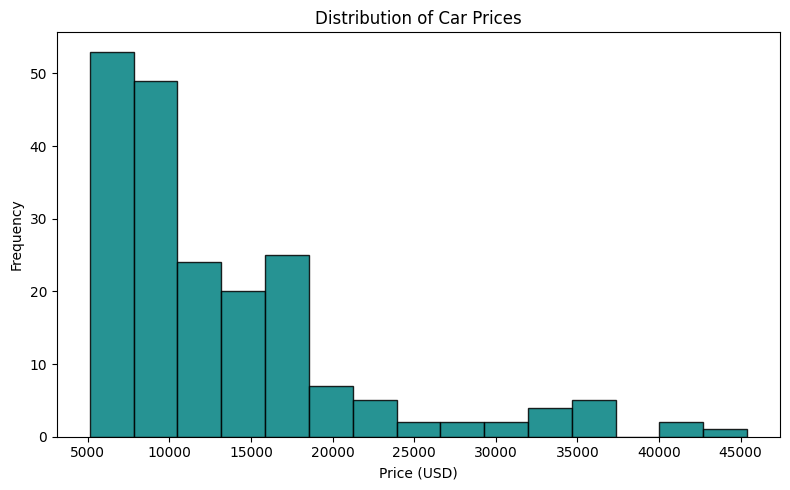

In [9]:
# Chart 1: Manufacturer-count bar chart
plt.figure(figsize=(10, 5))
make_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Number of Cars by Manufacturer (UCI Automobile Dataset)")
plt.xlabel("Manufacturer (make)")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("manufacturer_counts.png", dpi=150)
plt.show()

# Chart 2: Price histogram
plt.figure(figsize=(8, 5))
plt.hist(
    valid_prices_arr, bins=15, color="teal", edgecolor="black", alpha=0.85
)
plt.title("Distribution of Car Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("price_histogram.png", dpi=150)
plt.show()